# Figure 3. Structural features evaluated by FastRNA

What the scorer looks at and how it penalizes it. A: a G·C pair, ideal (top) and
distorted (bottom). B: the same for A·U. C: the curated-reference distribution of A·U cWW
H-bond distance that the scorer checks against, shaded by the penalty severity it applies, with three A·U pairs whose N6-O4 bond sits in the
short tail, at the peak, and in the long tail.

The structure images are read from `data/pymol/renders/` (1C_* for A-B, 3C_au_* for
the C examples); they are ray-traced from the PyMOL sessions in `data/pymol/sessions/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageOps

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if base.name.startswith("PARSE-RNA-Analysis") and (base / "data").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
RENDERS = ROOT / "data" / "pymol" / "renders"
CROPPED = RENDERS / "cropped"
CROPPED.mkdir(parents=True, exist_ok=True)

def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight",
    "savefig.pad_inches": 0.08,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.8, "pdf.fonttype": 42, "ps.fonttype": 42,
})

def letter(fig, ax, s, dx=-0.014, dy=0.004):
    box = ax.get_position()
    fig.text(box.x0 + dx, box.y1 + dy, s, fontsize=12, fontweight="bold",
             ha="left", va="bottom")

def letter_drawn(fig, ax, s, dx=-0.014, dy=0.004):
    """Letter placed against what the panel actually DRAWS.

    An equal-aspect panel keeps its gridspec box but paints inside a smaller
    rectangle, so the box's corner can sit far from the artwork -- which is why
    B's letter was stranded out in the margin. get_window_extent after a draw
    pass gives the painted rectangle instead.
    """
    fig.canvas.draw()
    pts = np.vstack([ln.get_xydata() for ln in ax.lines if len(ln.get_xydata())])
    x, y = ax.transData.transform((pts[:, 0].min(), pts[:, 1].max()))
    fx, fy = fig.transFigure.inverted().transform((x, y))
    fig.text(fx + dx, fy + dy, s, fontsize=12, fontweight="bold",
             ha="left", va="bottom")

def autocrop(name, pad=2, thresh=246):
    src, dst = RENDERS / name, CROPPED / name
    im = Image.open(src).convert("RGB")
    mask = ImageOps.grayscale(im).point(lambda v: 255 if v < thresh else 0)
    box = mask.getbbox()
    if box:
        l, t, r, b = box
        im = im.crop((max(0, l - pad), max(0, t - pad),
                      min(im.width, r + pad), min(im.height, b + pad)))
    im.save(dst)
    return dst

def show_pair(ax, name):
    ax.imshow(plt.imread(autocrop(f"{name}.png")))
    ax.set_xticks([]); ax.set_yticks([])
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(False)

print("renders:", ", ".join(sorted(p.stem for p in RENDERS.glob("1C_*.png"))))


renders: 1C_distorted_AU, 1C_distorted_GC, 1C_ideal_AU, 1C_ideal_GC


## Panel A
G·C cWW as the scorer sees it: ideal (top) and distorted (bottom)

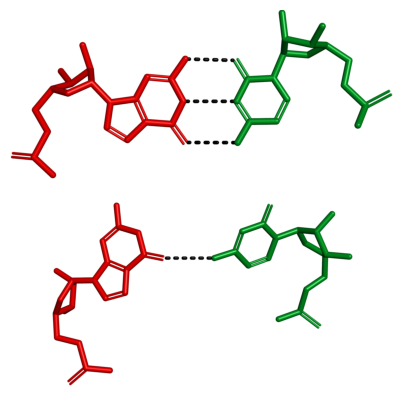

In [2]:
def draw_a(ax_top, ax_bottom):
    show_pair(ax_top, "1C_ideal_GC")
    show_pair(ax_bottom, "1C_distorted_GC")

fig, axes = plt.subplots(2, 1, figsize=(3.2, 3.2))
draw_a(*axes)
fig.tight_layout()
save(fig, "figures/main/figure3_A_GC_pairs.png")
plt.show()

## Panel B
A·U cWW: ideal (top) and distorted (bottom)

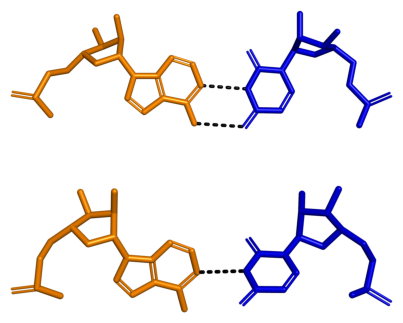

In [3]:
def draw_b(ax_top, ax_bottom):
    show_pair(ax_top, "1C_ideal_AU")
    show_pair(ax_bottom, "1C_distorted_AU")

fig, axes = plt.subplots(2, 1, figsize=(3.2, 3.2))
draw_b(*axes)
fig.tight_layout()
save(fig, "figures/main/figure3_B_AU_pairs.png")
plt.show()

## Calibration helpers (Panel C)
How a feature is penalized. The curve is the curated-reference KDE that the ProSco
distance table is built from (same rows, weights and bandwidth as
`scripts/data_gen/build_prosco_distributions.py`); the shading is the penalty severity
the scorer applies across it.

In [4]:
import json

import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import ConnectionPatch, Polygon
from matplotlib.ticker import MaxNLocator
from scipy.stats import gaussian_kde

data_file = lambda rel: ROOT / "data" / rel
_json = lambda rel: json.loads(data_file(rel).read_text())

PAIR, LW_CLASS = "A-U", "cWW"
FLIP = {"shear", "stagger", "buckle"}
PROSCO_PREFERRED = 5.0
SEV_CMAP = LinearSegmentedColormap.from_list("sev", ["0.82", "#F4D03F", "#E67E22", "#C0392B"])
SEV_NORM = Normalize(0, 1)
PROSCO = _json("reference/scoring_tables/prosco_distributions.json")["prosco_distributions"]
ZTAB = _json("reference/scoring_tables/z_tables.json")

def finish(ax):
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
    ax.tick_params(direction="out", width=0.8, length=3.5)
    return ax

import sys
sys.path.insert(0, str(ROOT / "scripts" / "data_gen"))
from build_prosco_distributions import BANDWIDTH_FACTOR, canonicalize_dataframe
from _vendor.hbond_distance_policy import select_distance_rows

def scoring_kde():
    """The exact KDE the ProSco distance table is built from
    (scripts/data_gen/build_prosco_distributions.py): curated reference set,
    canonical orientation, the bonds the distance policy scores (for A-U cWW every
    base-base bond), one PDB one vote, Gaussian KDE with bandwidth x 1.5, no trimming.
    Returns (values, weights, kde)."""
    df = pd.read_csv(data_file("reference/high_quality_features/hbonds.csv"))
    df = select_distance_rows(canonicalize_dataframe(df, "hbonds"))
    df = df[(df["bp_type"] == PAIR) & (df["lw_class"] == LW_CLASS)]
    v = df["distance"].to_numpy(float)
    ok = np.isfinite(v)
    v, ids = v[ok], df["pdb_id"][ok]
    w = per_pdb_weights(ids)
    kde = gaussian_kde(v, weights=w)
    kde.set_bandwidth(kde.factor * BANDWIDTH_FACTOR)
    return v, w, kde

def per_pdb_weights(pdb_ids):
    """One PDB, one vote: a 4,000-pair ribosome must not outvote 4,000 structures."""
    counts = pdb_ids.value_counts()
    return np.array([1.0 / counts[p] for p in pdb_ids])

def weighted_quantile(values, weights, q):
    order = np.argsort(values)
    v, w = values[order], weights[order]
    cum = np.cumsum(w)
    return float(np.interp(q * cum[-1], cum - w / 2, v))

_to_cg = lambda param, xs: xs

def _entry(table, group, param):
    c = table[group][param]
    return c.get(f"{PAIR}/{LW_CLASS}") or c.get("-".join(PAIR.split("-")[::-1]) + f"/{LW_CLASS}")

def prosco_at(group, param, xs_gc):
    xs = _to_cg(param, xs_gc)
    c = _entry(PROSCO, group, param)
    lo, hi, n = c["support_lo"], c["support_hi"], c["n_bins"]
    pb = np.array(c["prosco_per_bin"], float)
    return pb[np.clip(((xs - lo) / (hi - lo) * n).astype(int), 0, n - 1)]

def zprime_at(group, param, xs_gc):
    xs = _to_cg(param, xs_gc)
    c = _entry(ZTAB, group, param)
    M, sl, su = c["M"], c["sl"], c["su"]
    return (xs - M) / np.where(xs >= M, su, sl)

def severity_at(group, param, xs_gc):
    """min(1, |Z'|/5) * (5 - ProSco)/5, and exactly 0 inside the preferred tier."""
    pr, z = prosco_at(group, param, xs_gc), zprime_at(group, param, xs_gc)
    ramp = np.clip((PROSCO_PREFERRED - pr) / PROSCO_PREFERRED, 0.0, 1.0)
    return np.where(pr >= PROSCO_PREFERRED, 0.0, np.minimum(1.0, np.abs(z) / 5.0) * ramp)

def cal_panel(ax, kind, param, group, xlabel, tail=0.003, pad=0.05):
    """Reference density with the penalty-severity gradient clipped under it.

    The x-axis is cropped to where the density is above `tail` of its peak.
    """
    arr, w, kde = scoring_kde()

    xs = np.linspace(arr.min(), arr.max(), 1200)
    ys = kde(xs)
    seen = xs[ys >= tail * ys.max()]
    span = seen.max() - seen.min()
    xlo, xhi = seen.min() - pad * span, seen.max() + pad * span
    xs = np.linspace(xlo, xhi, 800)
    ys = kde(xs)
    sev = severity_at(group, param, xs)
    ymax = ys.max() * 1.10

    im = ax.imshow(SEV_CMAP(SEV_NORM(sev))[np.newaxis, :, :], extent=(xlo, xhi, 0, ymax),
                   origin="lower", aspect="auto", interpolation="bilinear", zorder=0)
    clip = Polygon(np.vstack([[xlo, 0], np.column_stack([xs, ys]), [xhi, 0]]),
                   closed=True, facecolor="none", edgecolor="none", zorder=0)
    ax.add_patch(clip)
    im.set_clip_path(clip)
    ax.plot(xs, ys, color="0.15", lw=1.3, zorder=2)
    ax.set_xlim(xlo, xhi)
    ax.set_ylim(0, ymax)
    ax.yaxis.set_major_locator(MaxNLocator(5))
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Density")
    finish(ax)
    return ax

def severity_colorbar(fig, axes, **kw):
    sm = ScalarMappable(norm=SEV_NORM, cmap=SEV_CMAP)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=axes, **kw)
    cb.set_label("Penalty severity", fontsize=8.5)
    cb.set_ticks([0, 0.5, 1.0])
    cb.set_ticklabels(["0", "0.5", "1"], fontsize=7.5)
    cb.outline.set_linewidth(0.8)
    return cb

## Panel C
Penalty severity across A·U cWW H-bond distance, with three A·U pairs placed below the
axis at their N6-O4 distance. The tail pairs come from structures outside the curated
set; all three were checked with the current C++ engine (`parse --details`, Oct 9 build).
Only distance is penalised in the tail pairs.

| render | pair | N6-O4 | N3-N1 | score |
|---|---|---|---|---|
| 3C_au_short | 9IMB D/A20-U5 | 2.37 Å | 2.53 Å | 92.8, distance (severity 0.72) |
| 3C_au_peak | 6YL5 C/A11-U28 (X-ray 1.7 Å) | 2.88 Å | 2.86 Å | 100, no issues |
| 3C_au_long | 3ICQ E/A66-U7 | 3.79 Å | 3.21 Å | 93.1, distance (severity 0.69) |

  [canonicalize/hbonds] swapped 357,706 rows into canonical orientation


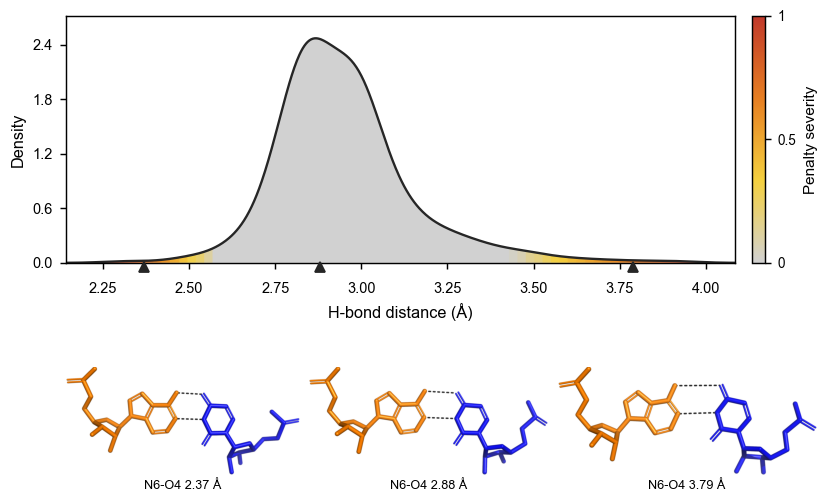

In [5]:
from matplotlib.transforms import offset_copy

EXAMPLES = [("3C_au_short", 2.37), ("3C_au_peak", 2.88), ("3C_au_long", 3.79)]

def draw_c(fig, ax, band_y0, band_h, gap=0.08):
    """Density panel plus the three example pairs in a band BELOW it.

    band_y0, band_h: the band in figure fractions. Each render sits under its N6-O4
    value (pushed sideways only if it would leave the axes or overlap a neighbour);
    the value is marked by a triangle just under the x-axis."""
    cal_panel(ax, "hbonds", "distance", "hbonds", "H-bond distance (Å)")
    ax.tick_params(axis="x", pad=7)
    W, H = fig.get_size_inches()
    box = ax.get_position()
    xlo, xhi = ax.get_xlim()
    kx, ky = ax.lines[0].get_xdata(), ax.lines[0].get_ydata()
    placed = []
    for name, d in EXAMPLES:
        w, h = Image.open(autocrop(f"{name}.png")).size
        iw = band_h * H * w / h / W
        cx = min(max(box.x0 + (d - xlo) / (xhi - xlo) * box.width, box.x0 + iw / 2),
                 box.x1 - iw / 2)
        if placed and cx - iw / 2 < placed[-1] + gap / W:
            cx = placed[-1] + gap / W + iw / 2
        placed.append(cx + iw / 2)
        ax_i = fig.add_axes([cx - iw / 2, band_y0, iw, band_h])
        show_pair(ax_i, name)
        ax_i.text(0.5, -0.04, f"N6-O4 {d:.2f} Å", transform=ax_i.transAxes,
                  ha="center", va="top", fontsize=7)
        ms = 5
        ax.plot([d], [0], marker="^", ms=ms, color="0.15", clip_on=False, zorder=5,
                transform=offset_copy(ax.transData, fig=fig, y=-ms / 2, units="points"))
    return ax

fig = plt.figure(figsize=(6.6, 3.8))
ax = fig.add_axes([0.1, 0.45, 0.78, 0.5])
draw_c(fig, ax, 0.02, 0.22)
cb = severity_colorbar(fig, [ax], cax=fig.add_axes([0.9, 0.45, 0.015, 0.5]))
save(fig, "figures/main/figure3_C_hbond_distance_examples.png")
plt.show()

## Combined figure


  [canonicalize/hbonds] swapped 357,706 rows into canonical orientation


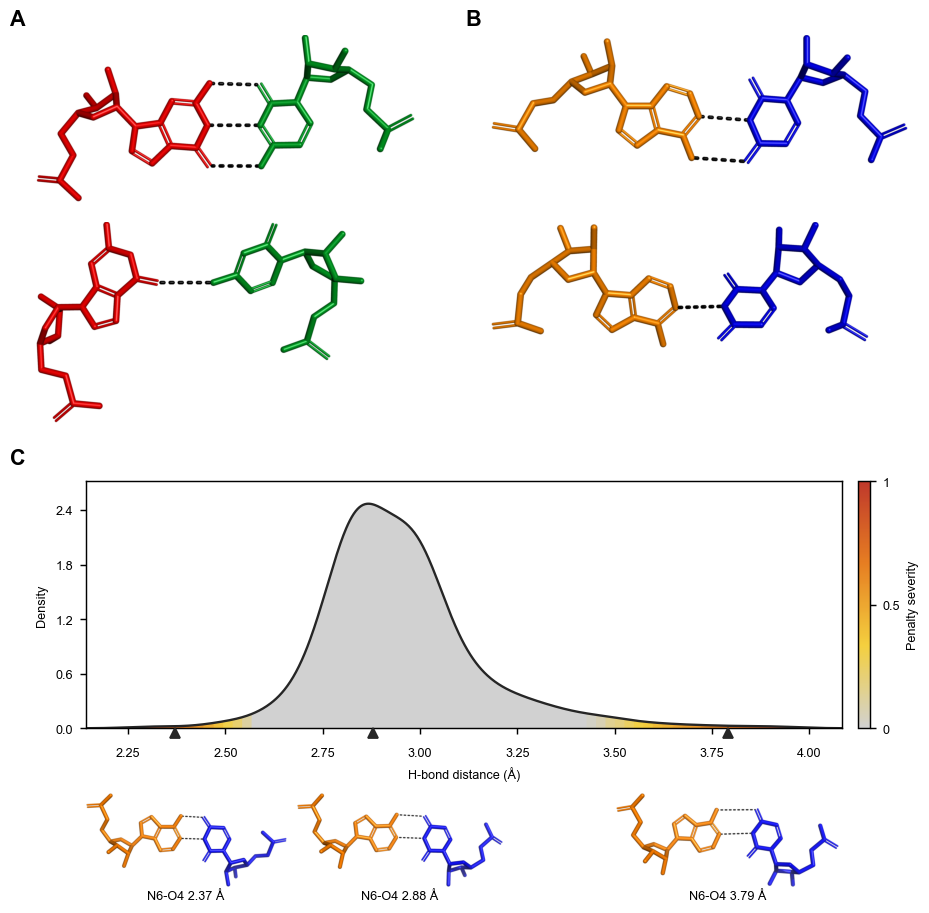

In [6]:
FIG_W, FIG_H = 7.2, 8.0
fig = plt.figure(figsize=(FIG_W, FIG_H))
inch = lambda x, y, w, h: [x / FIG_W, 1 - (y + h) / FIG_H, w / FIG_W, h / FIG_H]

COL_W, COL_GAP = 3.2, 0.3
X_A, X_B = 0.25, 0.25 + COL_W + COL_GAP
names = ("1C_ideal_GC", "1C_distorted_GC", "1C_ideal_AU", "1C_distorted_AU")
crop_px = {n: Image.open(autocrop(f"{n}.png")).size for n in names}
SCALE = COL_W / max(w for w, h in crop_px.values())

def render_box(name, x0, top):
    w, h = (v * SCALE for v in crop_px[name])
    return fig.add_axes(inch(x0, top, w, h)), h

TOP_1 = 0.3
ax_a1, h_a1 = render_box("1C_ideal_GC", X_A, TOP_1)
ax_b1, h_b1 = render_box("1C_ideal_AU", X_B, TOP_1)
TOP_2 = TOP_1 + max(h_a1, h_b1) + 0.15
ax_a2, h_a2 = render_box("1C_distorted_GC", X_A, TOP_2)
ax_b2, h_b2 = render_box("1C_distorted_AU", X_B, TOP_2)
draw_a(ax_a1, ax_a2)
draw_b(ax_b1, ax_b2)

C_TOP, C_H = TOP_2 + max(h_a2, h_b2) + 0.45, 1.9
C_X = 0.63   # puts C's y-axis label on the left edge of the A drawings
C_W = FIG_W - C_X - 0.75
BAND_TOP, BAND_H = C_TOP + C_H + 0.50, 0.72
ax_c = fig.add_axes(inch(C_X, C_TOP, C_W, C_H))
band = inch(C_X, BAND_TOP, C_W, BAND_H)
draw_c(fig, ax_c, band[1], band[3])
cax = fig.add_axes(inch(C_X + C_W + 0.12, C_TOP, 0.09, C_H))
cb = severity_colorbar(fig, [ax_c], cax=cax)
cb.set_ticklabels(["0", "0.5", "1"])

for ax, s, x in ((ax_a1, "A", X_A - 0.2), (ax_b1, "B", X_B - 0.2)):
    fig.text(x / FIG_W, ax.get_position().y1 + 0.005, s, fontsize=12, fontweight="bold",
             ha="left", va="bottom")
fig.text(0.05 / FIG_W, 1 - (C_TOP - 0.1) / FIG_H, "C", fontsize=12, fontweight="bold",
         ha="left", va="bottom")

TEXT_PT, LETTER_PT = 7, 12


def set_uniform_text(fig, size=TEXT_PT):
    import matplotlib.text as mtext
    for t in fig.findobj(mtext.Text):
        if t.get_fontsize() >= LETTER_PT and t.get_fontweight() in ("bold", 700):
            continue
        t.set_fontsize(size)


set_uniform_text(fig)
save(fig, "figures/main/figure3.png")
plt.show()